# 분포 시각화

- 데이터가 처음 주어졌을 때, 변수들이 어떤 요소로 어느 정도의 비율로 구성되어 있는지를 확인

- 분포 시각화는 양적 척도인지, 질적 척도인지에 따라 구분
    - 양적 척도
        - 막대 그래프, 선 그래프, 히스토그램
            - 히스토그램은 처음에는 구간을 20개 정도로 세세하게 나누어서 분포를 살펴본 다음, 시각적으로 봤을 때 정보의 손실이 커지기 전까지 조금씩 구간의 개수를 줄임
         
            - 구간이 너무 많으면 보기 어렵고, 너무 적으면 정보의 손실이 크기 때문에 시각화의 이점이 사라짐
         
    - 질적 척도
        - 구성이 단순한 경우
            - 파이차트, 도넛차트
                - 전체를 100%로 하여 구성 요소들의 분포 정도를 면적으로 표현
             
                - 시각적 표현만으로는 비율을 정확하게 알기 힘들기 때문에 수치를 함께 표시해 주는 것이 좋음
             
                - 도넛 차트는 가운데가 비어있어서 가운데 공간에 전체 값이나 단일 비율 값 등의 추가적인 정보를 삽입할 수 있음
             
        - 구성이 복잡한 경우
            - 트리맵 차트
                - 하나의 큰 사각형을 구성요소의 비율에 따라 작은 사각형으로 쪼개어 분포를 표현
             
                - 장점 : 사각형 안에 더 작은 사각형을 포함시켜서 위계구조를 표현할 수 있음
                    - 예) '바지' 영역을 '긴 바지' 와 '반바지' 로 분리하여 구성
                 
                - 단점 : 구성요소들 간의 규모 차이가 크면 표현이 어려울 수 있음
             
            - 와플 차트
                - 일정한 네모난 조각들로 분포를 표현
             
                - 트리맵 차트처럼 위계구조를 표현하지는 못함

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import plotly.express as px
from pywaffle import Waffle

In [2]:
df = pd.read_csv("./data/데이터분석_data/six_countries_height_samples.csv")

In [3]:
df.head()

,id,country,sex,height_cm
0,rhop00001,AUSTRALIA,man,189
1,rhop00002,AUSTRALIA,man,165
2,rhop00003,AUSTRALIA,man,189
3,rhop00004,AUSTRALIA,man,164
4,rhop00005,AUSTRALIA,man,192


In [4]:
df["country"].value_counts()

country
AUSTRALIA    178
DENMARK      178
ITALY        178
JAPAN        178
KOREA        178
TURKEY       178
Name: count, dtype: int64

- 6개국 성별별 신장 정보 데이터
    - 각 국가의 샘플 수는 모두 동일

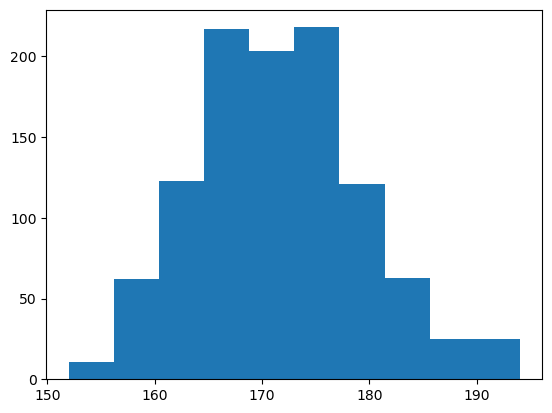

In [9]:
# 기본 히스토그램 시각화
df1 = df["height_cm"]

plt.hist(df1, bins = 10)
plt.show()

- 정규분포와 유사한 형태의 히스토그램
    - 봉우리가 2개로 나와 남성과 여성의 신장 분포가 다를 것으로 예상

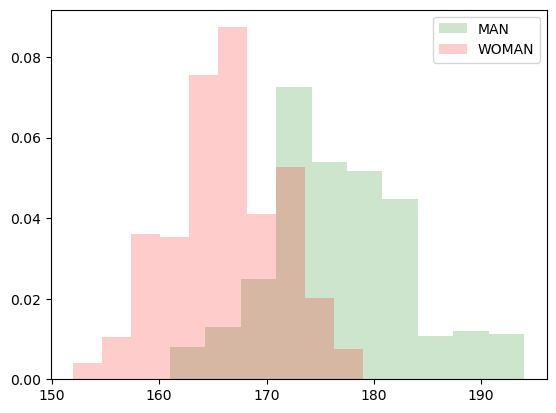

In [12]:
# 남성 여성 히스토그램 시각화

# 남성 여성 별도 데이터셋 생성
df1_1 = df.loc[df["sex"] == "man", "height_cm"]
df1_2 = df.loc[df["sex"] == "woman", "height_cm"]

plt.hist(df1_1, color = "green", alpha = 0.2, bins = 10, label = "MAN", density = True)
plt.hist(df1_2, color = "red", alpha = 0.2, bins = 10, label = "WOMAN", density = True)
plt.legend()
plt.show()

- 성별을 구분하여 히스토그램 시각화
    - alpha 옵션을 통해 불투명도를 조정하여 두 히스토그램 분포가 겹치는 부분을 효과적으로 표현

In [14]:
# 파이차트, 도넛차트 시각화를 위한 데이터 전처리
df2 = df[["country", "height_cm"]]

# 키 175 이상만 추출
df2 = df2[df2["height_cm"] >= 175]
df2 = df2.groupby("country").count().reset_index()
df2

,country,height_cm
0,AUSTRALIA,68
1,DENMARK,59
2,ITALY,67
3,JAPAN,46
4,KOREA,52
5,TURKEY,61


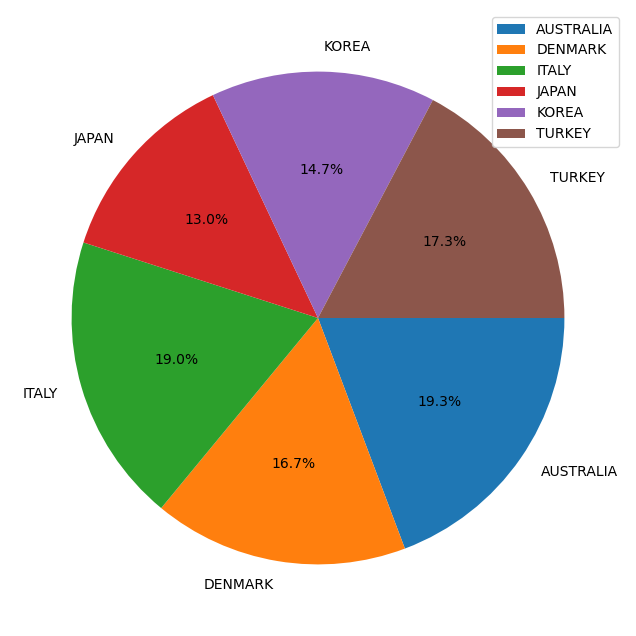

In [15]:
# 파이차트 시각화
fig = plt.figure(figsize = (8, 8))
ax = fig.add_subplot(1, 1, 1)

ax.pie(df2["height_cm"],
       labels = df2["country"],
       counterclock = False,
       autopct = "%.1f%%")

plt.legend()
plt.show()

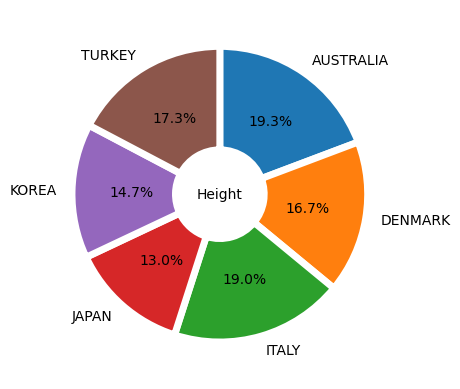

In [26]:
# 도넛차트 시각화

wedgeprops = {"width" : 0.7, "edgecolor" : "w", "linewidth" : 5} # 차트 형태 옵션

plt.pie(df2["height_cm"], labels = df2["country"], autopct = "%.1f%%", startangle = 90,
        counterclock = False, wedgeprops = wedgeprops)

plt.text(0, 0, "Height", ha = "center", va = "center")
plt.show()

In [28]:
# 트리맵 차트용 데이터셋 전처리
df3 = df.loc[df["height_cm"] >= 175, ["country", "sex", "height_cm"]]

# 국가, 성별 단위 신장 175cm 이상 데이터 개수 카운팅
df3 = df3.groupby(["country", "sex"]).count().reset_index()
df3

,country,sex,height_cm
0,AUSTRALIA,man,59
1,AUSTRALIA,woman,9
2,DENMARK,man,53
3,DENMARK,woman,6
4,ITALY,man,60
5,ITALY,woman,7
6,JAPAN,man,45
7,JAPAN,woman,1
8,KOREA,man,50
9,KOREA,woman,2


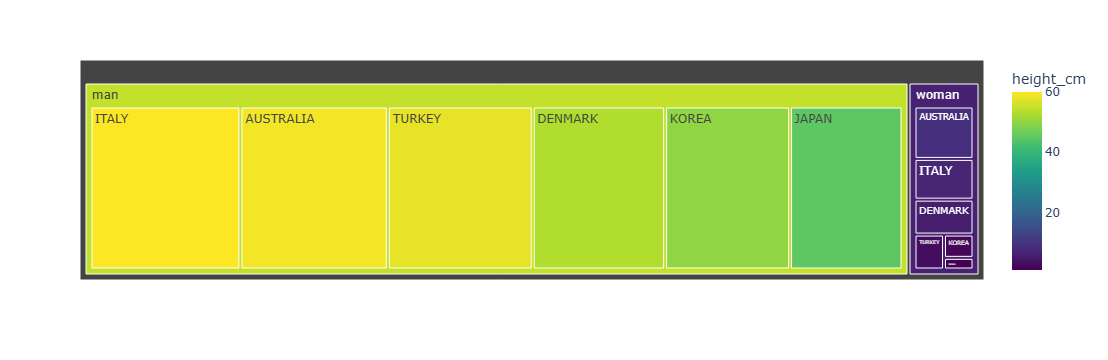

In [31]:
# 트리맵 차트 시각화
fig = px.treemap(df3,
                 path = ["sex", "country"],
                 values = "height_cm",
                 color = "height_cm",
                 color_continuous_scale = "viridis")
fig.show()

- 트리맵 차트는 위계구조를 표현하기 때문에 path 옵션으로 위계구조 순서별 컬럼을 입력

- 위의 차트에서는 성별로 먼저 구분하고, 그 안에서 국가별 분포를 표현

- 시각화된 트리맵 차트에서는 신장 175cm 이상 샘플의 비율을 나타내므로 남성-이탈리아 의 비중이 가장 높고, 여성-일본 의 비중이 가장 낮게 나옴

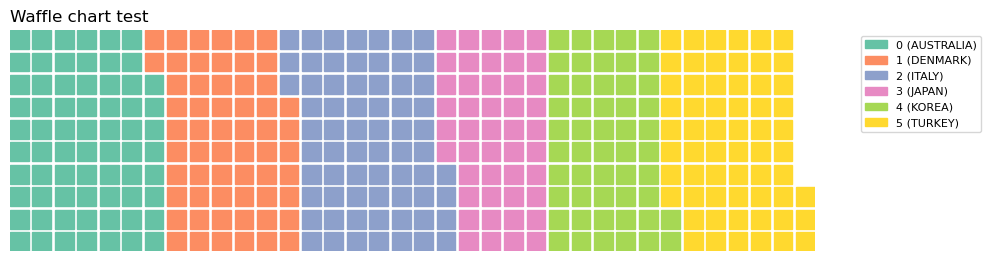

In [41]:
# 와플차트 시각화
fig = plt.figure(
    FigureClass = Waffle,
    plots = {
        111: {
            "values" : df2["height_cm"],
            "labels" : [f"{n} ({v})" for n, v in df2["country"].items()],
            "legend" : {"bbox_to_anchor" : (1.05, 1), "fontsize" : 8},
            "title" : {"label" : "Waffle chart test", "loc" : "left"}
        }
    },
    rows = 10,
    figsize = (10, 10)
)
plt.show()

- 각 국가의 비중이 작은 정사각형으로 표현됨